In [19]:
print("Mi primer proyecto de análisis de datos")

Mi primer proyecto de análisis de datos


# PROYECTO FINAL – ANÁLISIS DE DATOS

## Evolución de las emisiones mundiales de CO₂

**Estudiante:** Jhon Mario Rodríguez Flechas

**Programa:** Ciencia de Datos

**Institución:** Universidad Uniagraria

**Actividad:** Actividad 4

### Introducción

En este proyecto se realizará un análisis de las emisiones mundiales de dióxido de carbono (CO₂) a través de los años, utilizando datos de Our World in Data. Se desarrollarán procesos de limpieza de datos, visualización y un modelo de regresión lineal para identificar tendencias y analizar el comportamiento de las emisiones.

In [20]:
# Importar las herramientas necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Herramientas cargadas correctamente")

Herramientas cargadas correctamente


In [21]:

# Descargar la base de datos de emisiones de CO2

url = "https://ourworldindata.org/grapher/annual-co2-emissions-per-country.csv?v=1&csvType=full&useColumnShortNames=false"

df = pd.read_csv(
    url,
    storage_options={
        "User-Agent": "Our World In Data data fetch/1.0"
    }
)

print("Base de datos descargada correctamente")

Base de datos descargada correctamente


In [22]:
# Revisar las primeras filas de la base de datos

df.head(10)

,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0
5,Afghanistan,AFG,1954,102592.0
6,Afghanistan,AFG,1955,146560.0
7,Afghanistan,AFG,1956,175872.0
8,Afghanistan,AFG,1957,278464.0
9,Afghanistan,AFG,1958,311440.0


In [23]:
# Conocer el tamaño de nuestra base de datos

print("Cantidad de filas y columnas:", df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

Cantidad de filas y columnas: (30219, 4)

Nombres de las columnas:
['Entity', 'Code', 'Year', 'Annual CO₂ emissions']


In [24]:
# ANÁLISIS INICIAL DE LA CALIDAD DE LOS DATOS

print("INFORMACIÓN GENERAL")
df.info()

print("\nDATOS VACÍOS POR COLUMNA")
print(df.isnull().sum())

print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

print("\nESTADÍSTICAS GENERALES")
df.describe()

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30219 entries, 0 to 30218
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                30219 non-null  object 
 1   Code                  26889 non-null  object 
 2   Year                  30219 non-null  int64  
 3   Annual CO₂ emissions  30219 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 944.5+ KB

DATOS VACÍOS POR COLUMNA
Entity                     0
Code                    3330
Year                       0
Annual CO₂ emissions       0
dtype: int64

REGISTROS DUPLICADOS
0

ESTADÍSTICAS GENERALES


,Year,Annual CO₂ emissions
count,30219.000000,3.021900e+04
mean,1948.381879,4.164438e+08
std,60.265850,1.980808e+09
min,1750.000000,0.000000e+00
25%,1913.000000,3.407520e+05
50%,1963.000000,4.667949e+06
75%,1996.000000,5.161933e+07
max,2025.000000,3.899510e+10


In [25]:
# Identificar registros sin código

sin_codigo = df[df["Code"].isnull()]

print("Cantidad de registros sin código:")
print(len(sin_codigo))

print("\nPrimeros registros sin código:")
display(sin_codigo.head(20))

print("\nEntidades sin código:")
print(sin_codigo["Entity"].unique())

Cantidad de registros sin código:
3330

Primeros registros sin código:


,Entity,Code,Year,Annual CO₂ emissions
219,Africa (GCP),NaN,1850,0.0
220,Africa (GCP),NaN,1851,0.0
221,Africa (GCP),NaN,1852,0.0
222,Africa (GCP),NaN,1853,0.0
223,Africa (GCP),NaN,1854,0.0
224,Africa (GCP),NaN,1855,0.0
225,Africa (GCP),NaN,1856,0.0
226,Africa (GCP),NaN,1857,0.0
227,Africa (GCP),NaN,1858,0.0
228,Africa (GCP),NaN,1859,0.0



Entidades sin código:
['Africa (GCP)' 'Asia (GCP)' 'Asia (excl. China and India)'
 'Central America (GCP)' 'Europe (GCP)' 'Europe (excl. EU-27)'
 'Europe (excl. EU-28)' 'European Union (28)' 'International aviation'
 'International shipping' 'Kuwaiti Oil Fires (GCP)' 'Middle East (GCP)'
 'Non-OECD (GCP)' 'North America (GCP)' 'North America (excl. USA)'
 'OECD (GCP)' 'Oceania (GCP)' 'Ryukyu Islands (GCP)' 'South America (GCP)']


In [26]:
# Buscar los registros correspondientes al mundo

print(df[df["Entity"].str.contains("World", case=False, na=False)]["Entity"].unique())

['World']


In [27]:
# Seleccionar únicamente las emisiones mundiales

df_mundo = df[df["Entity"] == "World"].copy()

# Ordenar los datos por año
df_mundo = df_mundo.sort_values("Year")

print("Registros mundiales:", len(df_mundo))
display(df_mundo.head())

Registros mundiales: 276


,Entity,Code,Year,Annual CO₂ emissions
29668,World,OWID_WRL,1750,9305937.0
29669,World,OWID_WRL,1751,9407229.0
29670,World,OWID_WRL,1752,9505168.0
29671,World,OWID_WRL,1753,9610490.0
29672,World,OWID_WRL,1754,9733580.0


In [28]:
# LIMPIEZA DE LOS DATOS MUNDIALES

# Crear una copia para conservar los datos originales
df_limpio = df_mundo.copy()

# Convertir las columnas numéricas
df_limpio["Year"] = pd.to_numeric(
    df_limpio["Year"], errors="coerce"
)

df_limpio["Annual CO₂ emissions"] = pd.to_numeric(
    df_limpio["Annual CO₂ emissions"], errors="coerce"
)

# Eliminar registros con datos esenciales vacíos
df_limpio = df_limpio.dropna(
    subset=["Year", "Annual CO₂ emissions"]
)

# Eliminar posibles registros duplicados por año
df_limpio = df_limpio.drop_duplicates(subset=["Year"])

# Ordenar cronológicamente
df_limpio = df_limpio.sort_values("Year")

# Reiniciar los índices
df_limpio = df_limpio.reset_index(drop=True)

print("LIMPIEZA FINALIZADA")
print("Registros antes:", len(df_mundo))
print("Registros después:", len(df_limpio))
print("Datos vacíos:", df_limpio.isnull().sum().sum())
print("Duplicados:", df_limpio.duplicated().sum())

display(df_limpio.head())

LIMPIEZA FINALIZADA
Registros antes: 276
Registros después: 276
Datos vacíos: 0
Duplicados: 0


,Entity,Code,Year,Annual CO₂ emissions
0,World,OWID_WRL,1750,9305937.0
1,World,OWID_WRL,1751,9407229.0
2,World,OWID_WRL,1752,9505168.0
3,World,OWID_WRL,1753,9610490.0
4,World,OWID_WRL,1754,9733580.0


In [29]:
# Estadísticas de los datos limpios

df_limpio.describe()

,Year,Annual CO₂ emissions
count,276.000000,2.760000e+02
mean,1887.500000,6.836350e+09
std,79.818544,1.072812e+10
min,1750.000000,9.305937e+06
25%,1818.750000,5.088154e+07
50%,1887.500000,1.143421e+09
75%,1956.250000,7.978481e+09
max,2025.000000,3.899510e+10


## Limpieza de datos

Para el desarrollo del proyecto se seleccionaron los registros correspondientes a las emisiones mundiales de CO₂. Inicialmente se identificaron 276 registros correspondientes al periodo comprendido entre 1750 y 2025. Se revisaron los valores faltantes, los registros duplicados y los tipos de datos. Posteriormente, se organizaron los registros cronológicamente y se preparó una copia limpia de los datos para realizar el análisis estadístico y las visualizaciones.

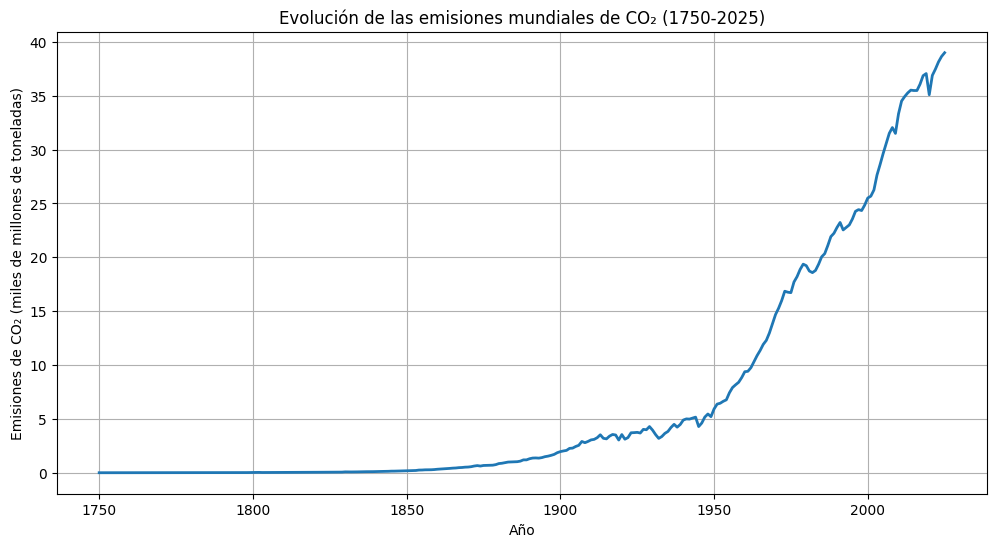

In [30]:
# GRAFICA 1: EVOLUCION DE LAS EMISIONES MUNDIALES DE CO2

plt.figure(figsize=(12, 6))

plt.plot(
    df_limpio["Year"],
    df_limpio["Annual CO₂ emissions"] / 1000000000,
    linewidth=2
)

plt.title("Evolución de las emisiones mundiales de CO₂ (1750-2025)")
plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (miles de millones de toneladas)")
plt.grid(True)

plt.show()

### Análisis de la gráfica 1: Evolución de las emisiones mundiales

La gráfica representa el comportamiento de las emisiones mundiales de dióxido de carbono entre los años 1750 y 2025. Se observa una tendencia general de crecimiento a lo largo del periodo estudiado. Durante los primeros años las emisiones eran relativamente bajas, pero con el paso del tiempo aumentaron considerablemente, especialmente durante el desarrollo industrial. Esto permite evidenciar el crecimiento de las emisiones de CO₂ a nivel mundial y su relación con las actividades humanas.

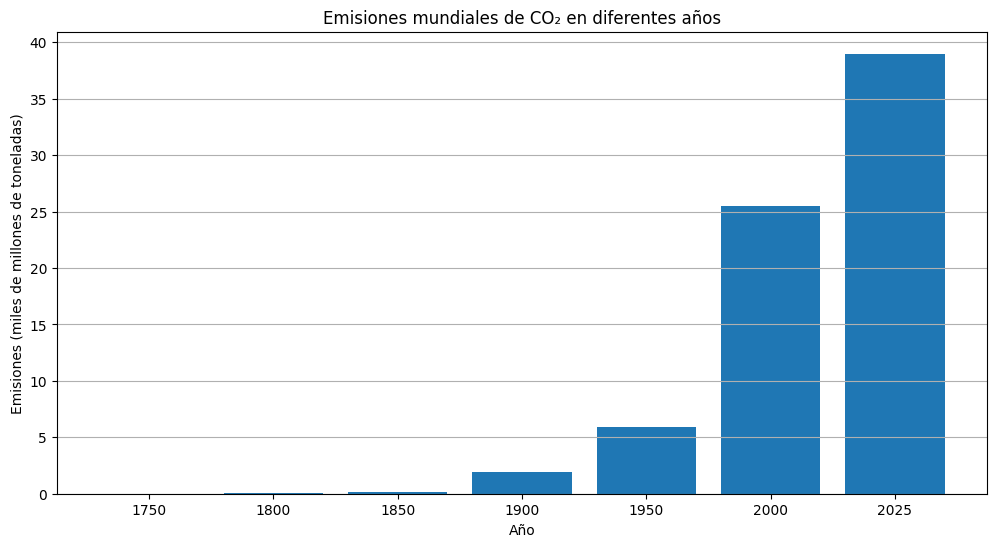

In [31]:
# GRAFICA 2: EMISIONES MUNDIALES POR PERIODOS

periodos = df_limpio[
    df_limpio["Year"].isin([1750, 1800, 1850, 1900, 1950, 2000, 2025])
]

plt.figure(figsize=(12, 6))

plt.bar(
    periodos["Year"].astype(str),
    periodos["Annual CO₂ emissions"] / 1000000000
)

plt.title("Emisiones mundiales de CO₂ en diferentes años")
plt.xlabel("Año")
plt.ylabel("Emisiones (miles de millones de toneladas)")
plt.grid(axis="y")

plt.show()

### Análisis de la gráfica 2: Comparación de emisiones por periodos

La gráfica permite comparar las emisiones mundiales de CO₂ en diferentes años, desde 1750 hasta 2025. Se evidencia que las emisiones aumentaron considerablemente con el paso del tiempo. Los valores más recientes presentan niveles superiores a los registrados en los primeros años. Esta comparación permite comprender la magnitud del crecimiento de las emisiones mundiales.

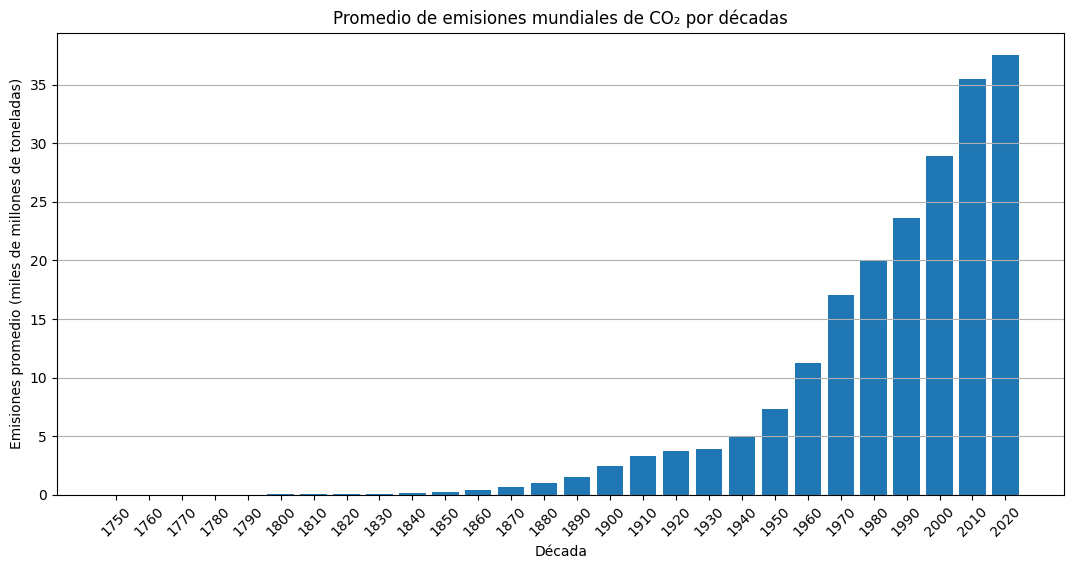

In [32]:
# GRAFICA 3: EMISIONES MUNDIALES POR DECADAS

df_limpio["Decada"] = (df_limpio["Year"] // 10) * 10

emisiones_decada = df_limpio.groupby("Decada")[
    "Annual CO₂ emissions"
].mean() / 1000000000

plt.figure(figsize=(13, 6))

plt.bar(emisiones_decada.index.astype(str), emisiones_decada.values)

plt.title("Promedio de emisiones mundiales de CO₂ por décadas")
plt.xlabel("Década")
plt.ylabel("Emisiones promedio (miles de millones de toneladas)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

### Análisis de la gráfica 3: Emisiones mundiales por décadas

La gráfica muestra el promedio de las emisiones mundiales de CO₂ agrupadas por décadas. Se observa que las emisiones han aumentado progresivamente a lo largo del tiempo. Durante las primeras décadas los niveles eran bajos, mientras que en las décadas más recientes se presentan valores considerablemente mayores. Esta visualización permite identificar con mayor claridad el crecimiento de las emisiones a largo plazo.

In [33]:
# REGRESIÓN LINEAL

from sklearn.linear_model import LinearRegression

# Variable independiente: año
X = df_limpio[["Year"]]

# Variable dependiente: emisiones de CO2
y = df_limpio["Annual CO₂ emissions"] / 1000000000

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Calcular las predicciones
predicciones = modelo.predict(X)

print("Modelo de regresión lineal creado correctamente")
print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)
print("Coeficiente R²:", modelo.score(X, y))

Modelo de regresión lineal creado correctamente
Pendiente: 0.10813028105786023
Intercepto: -197.2595551776568
Coeficiente R²: 0.6472246721328303


### Análisis de la regresión lineal

Se aplicó un modelo de regresión lineal para analizar la relación entre los años y las emisiones mundiales de CO₂. El modelo obtuvo un coeficiente de determinación (R²) de 0.6472, lo que indica que aproximadamente el 64.72 % de la variación de las emisiones puede ser explicada por el paso del tiempo mediante este modelo. La pendiente positiva muestra una tendencia general de crecimiento de las emisiones. Sin embargo, la regresión lineal no representa completamente los cambios que se han presentado durante todo el periodo estudiado.

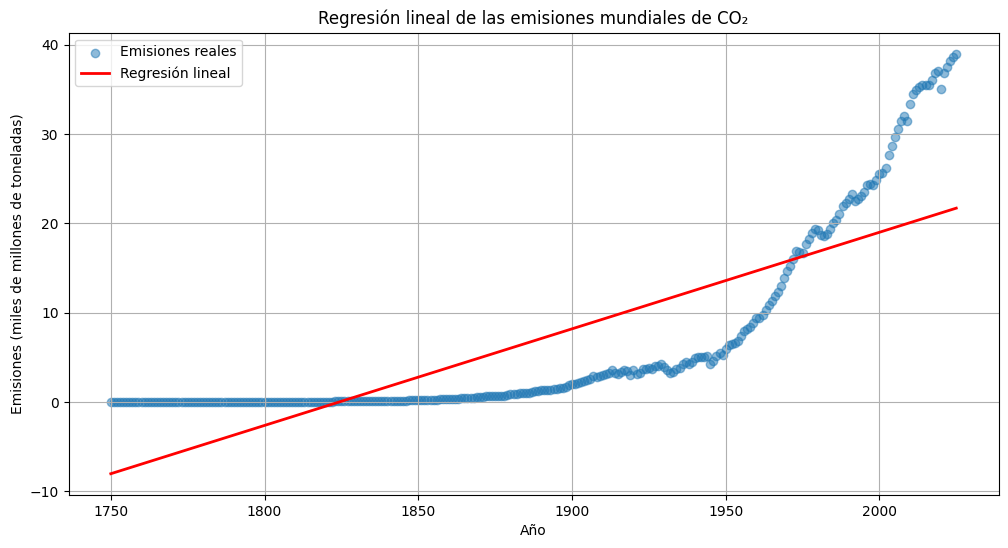

In [34]:
# GRAFICA DE REGRESION LINEAL

plt.figure(figsize=(12, 6))

plt.scatter(X, y, label="Emisiones reales", alpha=0.5)

plt.plot(
    X["Year"],
    predicciones,
    color="red",
    linewidth=2,
    label="Regresión lineal"
)

plt.title("Regresión lineal de las emisiones mundiales de CO₂")
plt.xlabel("Año")
plt.ylabel("Emisiones (miles de millones de toneladas)")
plt.legend()
plt.grid(True)
plt.show()

### Análisis de la gráfica de regresión lineal

La gráfica presenta los datos reales de las emisiones mundiales de CO₂ mediante puntos y la tendencia calculada por el modelo de regresión lineal mediante una línea roja. Se observa una tendencia creciente de las emisiones a través de los años. Sin embargo, los puntos no siguen exactamente la línea de regresión, lo que demuestra que el comportamiento de las emisiones no es completamente lineal. El modelo permite identificar una tendencia general, aunque no explica todos los cambios ocurridos durante el periodo analizado.

## Conclusiones

A través de este proyecto se analizaron las emisiones mundiales de dióxido de carbono (CO₂) durante el periodo comprendido entre 1750 y 2025, utilizando datos de Our World in Data.

Durante el desarrollo se realizó la limpieza y organización de los datos, se elaboraron diferentes gráficas para observar su comportamiento y se aplicó un modelo de regresión lineal.

Los resultados muestran que las emisiones mundiales de CO₂ han aumentado considerablemente con el paso del tiempo, especialmente durante los periodos más recientes. El modelo de regresión obtuvo un coeficiente R² de 0.6472, lo que indica que existe una relación entre el año y las emisiones, aunque el comportamiento real no es completamente lineal.

En conclusión, el análisis permitió aplicar herramientas básicas de ciencia de datos para comprender la evolución de las emisiones mundiales y reconocer la importancia de analizar información para identificar tendencias.